In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/FakeNewsProject"

os.makedirs(PROJECT_PATH, exist_ok=True)

print("Project folder ready.")

Project folder ready.


In [ ]:
os.listdir('/content/drive/MyDrive')

['Khadijah Irfan Resume (1).pdf',
 'Khadijah Irfan Resume.pdf',
 'khadijah Irfan 7th Semester CV.pdf',
 'Khadijah Irfan Resume-1.pdf',
 'khadijah Irfan CV (2).pdf',
 'khadijah Irfan CV (1).pdf',
 'khadijah Irfan CV.pdf',
 'DeepGuard',
 'Machine Learning Project',
 'Colab Notebooks',
 'FakeNewsProject']

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving WELFake_Dataset.csv to WELFake_Dataset.csv


In [ ]:
import shutil

shutil.copy(
    "WELFake_Dataset.csv",
    f"{PROJECT_PATH}/WELFake_Dataset.csv"
)

print("Dataset saved to Drive.")

FileNotFoundError: [Errno 2] No such file or directory: 'WELFake_Dataset.csv'

In [ ]:
os.listdir(PROJECT_PATH)

['WELFake_Dataset.csv',
 'lr_model.pkl',
 'nb_model.pkl',
 'tfidf.pkl',
 'final_dataset.csv']

In [ ]:
import pandas as pd

df = pd.read_csv("WELFake_Dataset.csv")

df.head()

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [ ]:
df.shape

(72134, 4)

In [ ]:
df.columns

Index(['Unnamed: 0', 'title', 'text', 'label'], dtype='object')

In [ ]:
df['label'].value_counts()


,count
label,
1,37106
0,35028


In [ ]:
df = df[['text', 'label']]
df.head()

,text,label
0,No comment is expected from Barack Obama Membe...,1
1,Did they post their votes for Hillary already?,1
2,"Now, most of the demonstrators gathered last ...",1
3,A dozen politically active pastors came here f...,0
4,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [ ]:
df.isnull().sum()

,0
text,39
label,0


In [ ]:
df = df.dropna(subset=['text', 'label'])

In [ ]:
df.isnull().sum()

,0
text,0
label,0


In [ ]:
import re
import string

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', '', text)
    text = text.strip()
    return text

In [ ]:
df['clean_text'] = df['text'].apply(clean_text)
df.head()

,text,label,clean_text
0,No comment is expected from Barack Obama Membe...,1,no comment is expected from barack obama membe...
1,Did they post their votes for Hillary already?,1,did they post their votes for hillary already
2,"Now, most of the demonstrators gathered last ...",1,now most of the demonstrators gathered last ni...
3,A dozen politically active pastors came here f...,0,a dozen politically active pastors came here f...
4,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1,the rs sarmat missile dubbed satan will repla...


In [ ]:
df[['text', 'clean_text', 'label']].head()

,text,clean_text,label
0,No comment is expected from Barack Obama Membe...,no comment is expected from barack obama membe...,1
1,Did they post their votes for Hillary already?,did they post their votes for hillary already,1
2,"Now, most of the demonstrators gathered last ...",now most of the demonstrators gathered last ni...,1
3,A dozen politically active pastors came here f...,a dozen politically active pastors came here f...,0
4,"The RS-28 Sarmat missile, dubbed Satan 2, will...",the rs sarmat missile dubbed satan will repla...,1


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words='english',
    max_df=0.7,
    min_df=5,
    ngram_range=(1,2)
)

X = tfidf.fit_transform(df['clean_text'])
y = df['label']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

In [ ]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_pred))
print(classification_report(y_test, lr_pred))

Logistic Regression Accuracy: 0.9423677092724877
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      7010
           1       0.93      0.96      0.94      7409

    accuracy                           0.94     14419
   macro avg       0.94      0.94      0.94     14419
weighted avg       0.94      0.94      0.94     14419



In [ ]:
print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))
print(classification_report(y_test, nb_pred))

Naive Bayes Accuracy: 0.8915320063804703
              precision    recall  f1-score   support

           0       0.88      0.90      0.89      7010
           1       0.90      0.88      0.89      7409

    accuracy                           0.89     14419
   macro avg       0.89      0.89      0.89     14419
weighted avg       0.89      0.89      0.89     14419



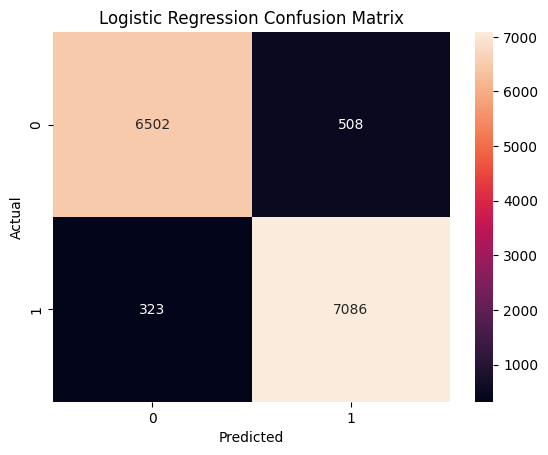

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, lr_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

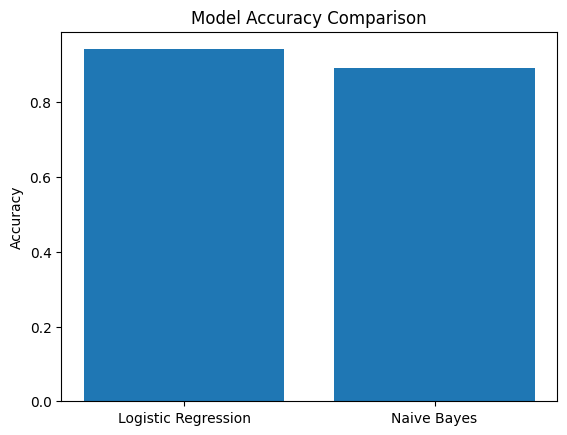

In [ ]:
models = ['Logistic Regression', 'Naive Bayes']
accuracy = [0.942, 0.891]

plt.figure()
plt.bar(models, accuracy)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.show()

In [ ]:
import joblib

joblib.dump(lr_model, "fake_news_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

In [ ]:
import joblib

joblib.dump(lr_model, "/content/drive/MyDrive/FakeNewsProject/lr_model.pkl")
joblib.dump(nb_model, "/content/drive/MyDrive/FakeNewsProject/nb_model.pkl")
joblib.dump(tfidf, "/content/drive/MyDrive/FakeNewsProject/tfidf.pkl")

['/content/drive/MyDrive/FakeNewsProject/tfidf.pkl']

In [ ]:
df.to_csv("/content/drive/MyDrive/FakeNewsProject/final_dataset.csv", index=False)

In [ ]:
import os

os.listdir("/content/drive/MyDrive/FakeNewsProject")

['WELFake_Dataset.csv',
 'lr_model.pkl',
 'nb_model.pkl',
 'tfidf.pkl',
 'final_dataset.csv']

In [ ]:
text = ["Breaking news: government announces new policy"]

vec = tfidf.transform(text)
prediction = lr_model.predict(vec)

print(prediction)

[1]


In [ ]:
import os

path = "/content/drive/MyDrive/FakeNewsProject"
os.listdir(path)

['WELFake_Dataset.csv',
 'lr_model.pkl',
 'nb_model.pkl',
 'tfidf.pkl',
 'final_dataset.csv']

In [ ]:
import joblib

model = joblib.load(path + "/lr_model.pkl")
tfidf = joblib.load(path + "/tfidf.pkl")

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr

def predict_news(text):
    vector = tfidf.transform([text])
    result = model.predict(vector)
    return "🚨 FAKE NEWS" if result[0] == 1 else "✅ REAL NEWS"

app = gr.Interface(fn=predict_news,
                   inputs="text",
                   outputs="text",
                   title="Fake News Detector")

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f0b6559d864a18d14c.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr
import joblib

# Load model and vectorizer
model = joblib.load("/content/drive/MyDrive/FakeNewsProject/lr_model.pkl")
tfidf = joblib.load("/content/drive/MyDrive/FakeNewsProject/tfidf.pkl")

# Prediction function
def predict_news(text):

    vector = tfidf.transform([text])
    result = model.predict(vector)

    if result[0] == 1:
        return "🚨 FAKE NEWS DETECTED"
    else:
        return "✅ REAL NEWS"

# Custom UI
with gr.Blocks(theme=gr.themes.Soft()) as app:

    gr.Markdown("""
    # 📰 Fake News Detection System

    ### 👩‍💻 Developed By
    - Khadijah Irfan
    - Zujajah Khan
    - Fatima Fiaz
    - Momina Aadil

    ---
    ### 📌 Project Information

    - **Dataset Used:** WELFake Dataset
    - **Model Used:** Logistic Regression
    - **Model Accuracy:** 94.23%
    - **Deployment Platform:** Hugging Face / Gradio

    ---
    """)

    news_input = gr.Textbox(
        lines=8,
        placeholder="Enter news article here...",
        label="News Article"
    )

    output = gr.Textbox(
        label="Prediction Result"
    )

    predict_btn = gr.Button("Predict News")

    predict_btn.click(
        fn=predict_news,
        inputs=news_input,
        outputs=output
    )

    gr.Markdown("""
    ---
    ### 📚 Developed as Machine Learning Project
    """)

app.launch()

/tmp/ipykernel_2686/4150223163.py:20: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as app:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://64e147c9c6ddccd2f9.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr
import joblib

# Load model and vectorizer
model = joblib.load("/content/drive/MyDrive/FakeNewsProject/lr_model.pkl")
tfidf = joblib.load("/content/drive/MyDrive/FakeNewsProject/tfidf.pkl")

# Prediction function
def predict_news(text):

    vector = tfidf.transform([text])
    result = model.predict(vector)

    if result[0] == 1:
        return "🚨 FAKE NEWS DETECTED"
    else:
        return "✅ REAL NEWS"

# Custom CSS
custom_css = """
body {
    background: linear-gradient(to right, #dbeafe, #bfdbfe);
}

.gradio-container {
    font-family: Arial, sans-serif;
}

h1 {
    text-align: center;
    color: #1e3a8a;
}

h3 {
    color: #1d4ed8;
}

textarea {
    background-color: #eff6ff !important;
    border-radius: 10px !important;
    border: 2px solid #60a5fa !important;
}

button {
    background-color: #2563eb !important;
    color: white !important;
    border-radius: 10px !important;
    font-size: 18px !important;
    padding: 10px !important;
}

button:hover {
    background-color: #1d4ed8 !important;
}

.output-textbox textarea {
    background-color: #dbeafe !important;
    color: #111827 !important;
    font-weight: bold !important;
    font-size: 18px !important;
}
"""

# UI
with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:

    gr.Markdown("""
    # 📰 Fake News Detection System

    ### 👩‍💻 Developed By
    - Khadijah Irfan
    - Zujajah Khan
    - Fatima Fiaz
    - Momina Aadil

    ---

    ### 📌 Project Information

    - **Dataset Used:** WELFake Dataset
    - **Model Used:** Logistic Regression
    - **Model Accuracy:** 94.23%
    - **Deployment Platform:** Hugging Face / Gradio

    ---
    """)

    news_input = gr.Textbox(
        lines=8,
        placeholder="Enter news article here...",
        label="📝 News Article"
    )

    output = gr.Textbox(
        label="🔍 Prediction Result",
        elem_classes="output-textbox"
    )

    predict_btn = gr.Button("🚀 Predict News")

    predict_btn.click(
        fn=predict_news,
        inputs=news_input,
        outputs=output
    )

    gr.Markdown("""
    ---
    ### 📚 Developed as Machine Learning Project
    """)

app.launch()

/tmp/ipykernel_2686/694715632.py:65: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:
/tmp/ipykernel_2686/694715632.py:65: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bca7ddd8d2935c575b.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr
import joblib

# Load trained model and TF-IDF vectorizer
model = joblib.load("/content/drive/MyDrive/FakeNewsProject/lr_model.pkl")
tfidf = joblib.load("/content/drive/MyDrive/FakeNewsProject/tfidf.pkl")

# Prediction Function
def predict_news(text):

    vector = tfidf.transform([text])
    result = model.predict(vector)

    if result[0] == 1:
        return "🚨 FAKE NEWS DETECTED"
    else:
        return "✅ REAL NEWS"


# Custom CSS Styling
custom_css = """
.gradio-container {
    background: linear-gradient(to right, #dbeafe, #93c5fd) !important;
    min-height: 100vh;
    font-family: Arial, sans-serif;
    padding: 20px;
}

#title {
    text-align: center;
    color: #1e3a8a;
    font-size: 40px;
    font-weight: bold;
}

#subtitle {
    text-align: center;
    color: #1d4ed8;
    font-size: 18px;
}

.info-box {
    background-color: #eff6ff;
    border-radius: 15px;
    padding: 15px;
    margin-top: 10px;
    border: 2px solid #60a5fa;
}

textarea {
    background-color: #f8fbff !important;
    border: 2px solid #3b82f6 !important;
    border-radius: 12px !important;
    font-size: 16px !important;
}

button {
    background-color: #2563eb !important;
    color: white !important;
    border-radius: 12px !important;
    border: none !important;
    font-size: 18px !important;
    padding: 12px !important;
    font-weight: bold !important;
}

button:hover {
    background-color: #1d4ed8 !important;
}

.output-text textarea {
    background-color: #dbeafe !important;
    color: #111827 !important;
    font-weight: bold !important;
    font-size: 20px !important;
    border-radius: 12px !important;
}

.footer {
    text-align: center;
    color: #1e3a8a;
    font-size: 16px;
    margin-top: 20px;
    font-weight: bold;
}
"""

# Gradio UI
with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:

    gr.Markdown(
        """
        <div id="title">📰 Fake News Detection System</div>
        <div id="subtitle">
        AI-powered system to detect whether news is REAL or FAKE
        </div>
        """
    )

    gr.Markdown(
        """
        <div class="info-box">

        ### 👩‍💻 Developed By
        - Khadijah Irfan
        - Zujajah Khan
        - Fatima Fiaz
        - Momina Aadil

        ---

        ### 📌 Project Information

        - Dataset Used: WELFake Dataset
        - Model Used: Logistic Regression
        - Model Accuracy: 94.23%
        - Deployment Platform: Gradio / Hugging Face

        </div>
        """
    )

    news_input = gr.Textbox(
        lines=8,
        placeholder="Enter news article here...",
        label="📝 News Article"
    )

    output = gr.Textbox(
        label="🔍 Prediction Result",
        elem_classes="output-text"
    )

    predict_btn = gr.Button("🚀 Predict News")

    predict_btn.click(
        fn=predict_news,
        inputs=news_input,
        outputs=output
    )

    gr.Markdown(
        """
        <div class="footer">
        📚 Developed as Machine Learning Project
        </div>
        """
    )

# Launch App
app.launch(debug=True)

/tmp/ipykernel_2686/861291262.py:89: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:
/tmp/ipykernel_2686/861291262.py:89: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://a6e9aa8b056329a784.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import os

path = "/content/drive/MyDrive/FakeNewsProject"

os.listdir(path)

['WELFake_Dataset.csv',
 'lr_model.pkl',
 'nb_model.pkl',
 'tfidf.pkl',
 'final_dataset.csv']

In [ ]:
!pip install gradio

In [ ]:
import joblib

model = joblib.load(path + "/lr_model.pkl")
tfidf = joblib.load(path + "/tfidf.pkl")

In [ ]:
sample = ["The government announced a new education policy today."]

vec = tfidf.transform(sample)

prediction = model.predict(vec)

print(prediction)

[1]


In [ ]:
def predict_news(text):

    vector = tfidf.transform([text])
    result = model.predict(vector)

    if result[0] == 1:
        return "✅ REAL NEWS"
    else:
        return "🚨 FAKE NEWS DETECTED"

In [ ]:
app.launch(debug=True)

NameError: name 'app' is not defined

In [ ]:
import gradio as gr
import joblib

# Load model and vectorizer
model = joblib.load("/content/drive/MyDrive/FakeNewsProject/lr_model.pkl")
tfidf = joblib.load("/content/drive/MyDrive/FakeNewsProject/tfidf.pkl")

# Prediction function
def predict_news(text):

    vector = tfidf.transform([text])
    result = model.predict(vector)

    if result[0] == 1:
        return "✅ REAL NEWS"
    else:
        return "🚨 FAKE NEWS DETECTED"

# Custom CSS
custom_css = """
.gradio-container {
    background: linear-gradient(to right, #dbeafe, #93c5fd) !important;
    min-height: 100vh;
    font-family: Arial, sans-serif;
    padding: 20px;
}

#title {
    text-align: center;
    color: #1e3a8a;
    font-size: 40px;
    font-weight: bold;
}

#subtitle {
    text-align: center;
    color: #1d4ed8;
    font-size: 18px;
}

.info-box {
    background-color: #eff6ff;
    border-radius: 15px;
    padding: 15px;
    margin-top: 10px;
    border: 2px solid #60a5fa;
}

textarea {
    background-color: #f8fbff !important;
    border: 2px solid #3b82f6 !important;
    border-radius: 12px !important;
    font-size: 16px !important;
}

button {
    background-color: #2563eb !important;
    color: white !important;
    border-radius: 12px !important;
    border: none !important;
    font-size: 18px !important;
    padding: 12px !important;
    font-weight: bold !important;
}

button:hover {
    background-color: #1d4ed8 !important;
}

.output-text textarea {
    background-color: #dbeafe !important;
    color: #111827 !important;
    font-weight: bold !important;
    font-size: 20px !important;
    border-radius: 12px !important;
}

.footer {
    text-align: center;
    color: #1e3a8a;
    font-size: 16px;
    margin-top: 20px;
    font-weight: bold;
}
"""

# Build UI
with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:

    gr.Markdown(
        """
        <div id="title">📰 Fake News Detection System</div>

        <div id="subtitle">
        AI-powered system to detect whether news is REAL or FAKE
        </div>
        """
    )

    gr.Markdown(
        """
        <div class="info-box">

        ### 👩‍💻 Developed By
        - Khadijah Irfan
        - Zujajah Khan
        - Fatima Fiaz
        - Momina Aadil

        ---

        ### 📌 Project Information

        - Dataset Used: WELFake Dataset
        - Model Used: Logistic Regression
        - Model Accuracy: 94.23%
        - Deployment Platform: Gradio / Hugging Face

        </div>
        """
    )

    news_input = gr.Textbox(
        lines=8,
        placeholder="Enter news article here...",
        label="📝 News Article"
    )

    output = gr.Textbox(
        label="🔍 Prediction Result",
        elem_classes="output-text"
    )

    predict_btn = gr.Button("🚀 Predict News")

    predict_btn.click(
        fn=predict_news,
        inputs=news_input,
        outputs=output
    )

    gr.Markdown(
        """
        <div class="footer">
        📚 Developed as Machine Learning Project
        </div>
        """
    )

# Launch app
app.launch(debug=True)

/tmp/ipykernel_19059/1890231426.py:88: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:
/tmp/ipykernel_19059/1890231426.py:88: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://9d446735f68a433686.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://9d446735f68a433686.gradio.live


In [ ]:
sample1 = ["Aliens secretly landed in Lahore and are controlling the weather."]
sample2 = ["The government announced a new education policy today."]

vec1 = tfidf.transform(sample1)
vec2 = tfidf.transform(sample2)

pred1 = model.predict(vec1)
pred2 = model.predict(vec2)

print("Fake-style news prediction:", pred1)
print("Real-style news prediction:", pred2)

Fake-style news prediction: [1]
Real-style news prediction: [1]


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

model.fit(X_train, y_train)

NameError: name 'X_train' is not defined

In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/FakeNewsProject/final_dataset.csv")

In [ ]:
X = df['clean_text']

y = df['label']

In [ ]:
import joblib

tfidf = joblib.load("/content/drive/MyDrive/FakeNewsProject/tfidf.pkl")

X = tfidf.transform(X)

ValueError: np.nan is an invalid document, expected byte or unicode string.

In [ ]:
df = df.dropna(subset=['clean_text'])

In [ ]:
X = df['clean_text']

y = df['label']

X = tfidf.transform(X)

In [ ]:
import joblib
tfidf = joblib.load("/content/drive/MyDrive/FakeNewsProject/tfidf.pkl")


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Accuracy: 0.9496948010945064
              precision    recall  f1-score   support

           0       0.96      0.94      0.95      7023
           1       0.94      0.96      0.95      7230

    accuracy                           0.95     14253
   macro avg       0.95      0.95      0.95     14253
weighted avg       0.95      0.95      0.95     14253



In [ ]:
sample1 = ["Aliens secretly landed in Lahore and are controlling the weather."]
sample2 = ["The government announced a new education policy today."]

vec1 = tfidf.transform(sample1)
vec2 = tfidf.transform(sample2)

pred1 = model.predict(vec1)
pred2 = model.predict(vec2)

print("Fake-style prediction:", pred1)
print("Real-style prediction:", pred2)

Fake-style prediction: [1]
Real-style prediction: [1]


In [ ]:
df['label'].value_counts()

,count
label,
1,36237
0,35027


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/FakeNewsProject/final_dataset.csv")

df = df.dropna(subset=['clean_text'])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'],
    df['label'],
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_vec)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9382586122219884
              precision    recall  f1-score   support

           0       0.94      0.93      0.94      7023
           1       0.93      0.95      0.94      7230

    accuracy                           0.94     14253
   macro avg       0.94      0.94      0.94     14253
weighted avg       0.94      0.94      0.94     14253



In [ ]:
sample1 = ["Aliens secretly landed in Lahore and are controlling the weather."]
sample2 = ["The government announced a new education policy today."]

print(model.predict(tfidf.transform(sample1)))
print(model.predict(tfidf.transform(sample2)))

[1]
[1]


In [ ]:
df['label'].unique()

array([1, 0])

In [ ]:
df[['clean_text', 'label']].sample(10)

,clean_text,label
50953,episode of sunday wire show resumes this nove...,1
68888,washington reuters us secretary of state rex ...,0
2104,washington reuters us president barack obama ...,0
46053,share this \ndespite being dead for over year...,1
20472,seoul reuters north korea on thursday warned ...,0
34779,beijing reuters china said on monday that it ...,0
33078,moscow reuters russia is open to working with...,0
29039,washington reuters north korea would need to ...,0
45691,a press release by bernards township nj is pro...,1
46236,gettsyburg pa reuters us republican president...,0


In [ ]:
print(df['label'].dtype)
print(df['label'].value_counts())

int64
label
1    36237
0    35027
Name: count, dtype: int64


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/FakeNewsProject/final_dataset.csv")
df = df.dropna(subset=['clean_text'])

X = df['clean_text']
y = df['label']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y   # 🔥 IMPORTANT FIX
)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_vec)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9380481302181997
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      7005
           1       0.93      0.95      0.94      7248

    accuracy                           0.94     14253
   macro avg       0.94      0.94      0.94     14253
weighted avg       0.94      0.94      0.94     14253



In [ ]:
sample1 = ["Aliens secretly landed in Lahore and are controlling the weather."]
sample2 = ["The government announced a new education policy today."]

print(model.predict(tfidf.transform(sample1)))
print(model.predict(tfidf.transform(sample2)))

[1]
[1]


In [ ]:
import numpy as np

print("Class balance in training:")
print(np.unique(y_train, return_counts=True))

print("\nModel classes:")
print(model.classes_)

Class balance in training:
(array([0, 1]), array([28022, 28989]))

Model classes:
[0 1]


In [ ]:
print(model.predict(X_test_vec[:10]))
print(y_test[:10].values)

[1 1 0 1 1 1 1 0 1 1]
[1 1 0 1 1 1 1 0 1 1]


In [ ]:
import joblib

joblib.dump(model, "/content/drive/MyDrive/FakeNewsProject/final_model.pkl")
joblib.dump(tfidf, "/content/drive/MyDrive/FakeNewsProject/final_tfidf.pkl")

['/content/drive/MyDrive/FakeNewsProject/final_tfidf.pkl']

In [ ]:
model.predict(tfidf.transform(["The national assembly passed a new education bill focusing on digital learning in schools."]))

array([1])

In [ ]:
text = ["The government announced new economic reforms to reduce inflation."]

vector = tfidf.transform(text)
prediction = model.predict(vector)

print(prediction)

[1]


In [ ]:
samples = [
    "The Prime Minister announced new policies for education reform.",
    "Aliens secretly landed in Lahore and are controlling the weather.",
    "The central bank increased interest rates to control inflation.",
    "A viral post claimed humans can fly after drinking a special tea."
]

vectors = tfidf.transform(samples)
predictions = model.predict(vectors)

for text, pred in zip(samples, predictions):
    print(text)
    print("Prediction:", pred)
    print("-"*50)

The Prime Minister announced new policies for education reform.
Prediction: 0
--------------------------------------------------
Aliens secretly landed in Lahore and are controlling the weather.
Prediction: 1
--------------------------------------------------
The central bank increased interest rates to control inflation.
Prediction: 1
--------------------------------------------------
A viral post claimed humans can fly after drinking a special tea.
Prediction: 1
--------------------------------------------------


In [ ]:
y_pred = model.predict(X_test_vec)

from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9380481302181997
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      7005
           1       0.93      0.95      0.94      7248

    accuracy                           0.94     14253
   macro avg       0.94      0.94      0.94     14253
weighted avg       0.94      0.94      0.94     14253



In [ ]:
def predict_news(text):

    vector = tfidf.transform([text])
    result = model.predict(vector)[0]

    if result == 0:
        return "✅ REAL NEWS"
    else:
        return "🚨 FAKE NEWS DETECTED"

In [ ]:
samples = [
    "The government announced a new healthcare policy to improve hospital facilities.",
    "Aliens have officially taken control of Pakistan’s weather system.",
    "The central bank raised interest rates to control inflation.",
    "A secret underground city of robots was discovered beneath Lahore."
]

for text in samples:
    vector = tfidf.transform([text])
    pred = model.predict(vector)[0]

    print(text)
    print("Prediction:", pred)
    print("-"*60)

The government announced a new healthcare policy to improve hospital facilities.
Prediction: 1
------------------------------------------------------------
Aliens have officially taken control of Pakistan’s weather system.
Prediction: 1
------------------------------------------------------------
The central bank raised interest rates to control inflation.
Prediction: 1
------------------------------------------------------------
A secret underground city of robots was discovered beneath Lahore.
Prediction: 1
------------------------------------------------------------


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/FakeNewsProject/final_dataset.csv")
df = df.dropna(subset=['clean_text'])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'],
    df['label'],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1,2),
    stop_words='english'
)

X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

y_pred = model.predict(X_test_vec)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

ValueError: X has 30000 features, but LogisticRegression is expecting 5000 features as input.

In [ ]:
print("Training accuracy:", model.score(X_train_vec, y_train))
print("Test accuracy:", model.score(X_test_vec, y_test))

ValueError: X has 30000 features, but LogisticRegression is expecting 5000 features as input.

In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/FakeNewsProject/final_dataset.csv")

df = df.dropna(subset=['clean_text'])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'],
    df['label'],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1,2),
    stop_words='english'
)

X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_vec)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9460464463621694
              precision    recall  f1-score   support

           0       0.96      0.93      0.94      7005
           1       0.94      0.96      0.95      7248

    accuracy                           0.95     14253
   macro avg       0.95      0.95      0.95     14253
weighted avg       0.95      0.95      0.95     14253



In [ ]:
samples = [
    "The government announced new healthcare reforms to improve hospitals.",
    "Aliens secretly control weather using hidden satellite systems.",
    "The central bank raised interest rates to control inflation.",
    "A viral post claimed humans can become invisible by drinking tea."
]

for text in samples:
    pred = model.predict(tfidf.transform([text]))[0]
    print(text)
    print("Prediction:", pred)
    print("-"*60)

The government announced new healthcare reforms to improve hospitals.
Prediction: 1
------------------------------------------------------------
Aliens secretly control weather using hidden satellite systems.
Prediction: 1
------------------------------------------------------------
The central bank raised interest rates to control inflation.
Prediction: 1
------------------------------------------------------------
A viral post claimed humans can become invisible by drinking tea.
Prediction: 1
------------------------------------------------------------


In [ ]:
import os

os.remove("/content/drive/MyDrive/FakeNewsProject/lr_model.pkl")
os.remove("/content/drive/MyDrive/FakeNewsProject/tfidf.pkl")

In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/FakeNewsProject/final_dataset.csv")
df = df.dropna(subset=['clean_text'])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'],
    df['label'],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1,2),
    stop_words='english'
)

X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
samples = [
    "The government announced new healthcare reforms.",
    "Aliens secretly control weather using satellites.",
    "The central bank raised interest rates.",
    "A viral post claimed humans can become invisible."
]

print(model.predict(tfidf.transform(samples)))

[1 1 1 1]


In [ ]:
print("Train labels:", y_train.value_counts())
print("Unique labels:", y_train.unique())

Train labels: label
1    28989
0    28022
Name: count, dtype: int64
Unique labels: [0 1]


In [ ]:
print(X_train_vec.shape)
print(len(tfidf.get_feature_names_out()))

(57011, 30000)
30000


In [ ]:
print(model)

LogisticRegression(max_iter=1000)


In [ ]:
print(model.predict(X_test_vec[:10]))
print(y_test[:10].values)

[1 1 0 1 1 1 1 0 1 0]
[1 1 0 1 1 1 1 0 1 1]


In [ ]:
text = [
    "The government announced new healthcare reforms.",
    "Aliens control weather using satellites."
]

vec = tfidf.transform(text)
print("Vector shape:", vec.shape)
print("Prediction:", model.predict(vec))

Vector shape: (2, 30000)
Prediction: [1 1]


In [ ]:
import os
os.remove("lr_model.pkl")
os.remove("tfidf.pkl")

FileNotFoundError: [Errno 2] No such file or directory: 'lr_model.pkl'

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"   # 🔥 FIX
)

In [ ]:
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1,3),   # 🔥 better context
    stop_words='english'
)

In [ ]:
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

model.fit(X_train_vec, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
text = [
    "The government announced new healthcare reforms.",
    "Aliens control weather using satellites."
]

vec = tfidf.transform(text)
print(model.predict(vec))

[1 1]


In [ ]:
import numpy as np

texts = [
    "The government announced new healthcare reforms to improve hospitals.",
    "Aliens secretly control weather using satellites.",
    "The central bank raised interest rates to control inflation.",
    "A viral post claimed humans can become invisible by drinking tea."
]

X_vec = tfidf.transform(texts)

print("Shape:", X_vec.shape)
print("Non-zero values per sample:")
print(np.array([x.nnz for x in X_vec]))

Shape: (4, 50000)
Non-zero values per sample:
[9 6 7 7]


In [ ]:
print("Class distribution prediction:")
print(model.predict(X_test_vec).tolist().count(0),
      model.predict(X_test_vec).tolist().count(1))

Class distribution prediction:
6839 7414


In [ ]:
print("Model intercept:", model.intercept_)

Model intercept: [1.98295663]


In [ ]:
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1,3),
    min_df=2,          # 🔥 important fix
    max_df=0.9,        # removes overly common noise words
    stop_words='english'
)

In [ ]:
LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
TfidfVectorizer(
    max_features=50000,
    ngram_range=(1,3),
    min_df=2,
    max_df=0.85
)

TfidfVectorizer(max_df=0.85, max_features=50000, min_df=2, ngram_range=(1, 3))

In [ ]:
from sklearn.calibration import CalibratedClassifierCV

model = CalibratedClassifierCV(model)
model.fit(X_train_vec, y_train)

CalibratedClassifierCV(estimator=LogisticRegression(class_weight='balanced',
                                                    max_iter=1000))

In [ ]:
texts = [
    "The government announced new healthcare reforms to improve hospitals.",
    "Aliens secretly control weather using satellites.",
    "The central bank raised interest rates to control inflation.",
    "A viral post claimed humans can become invisible by drinking tea."
]

vec = tfidf.transform(texts)

pred = model.predict(vec)

print(pred)

NotFittedError: Vocabulary not fitted or provided

In [ ]:
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1,3),
    stop_words='english'
)

In [ ]:
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

In [ ]:
model.fit(X_train_vec, y_train)

In [ ]:
vec = tfidf.transform([
    "The government announced new reforms",
    "Aliens control weather systems"
])

print(model.predict(vec))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
base_path = "/content/drive/MyDrive/TEXT MODULE"

In [ ]:
import os

print(os.listdir(base_path))

['WELFake_Dataset.csv', 'final_svm_model.pkl', 'final_tfidf.pkl', 'fake_news_model.pkl', 'tfidf.pkl', 'naive_bayes_model.pkl', 'tfidf_nb.pkl']


In [ ]:
import joblib
import pandas as pd

In [ ]:
model = joblib.load(base_path + "/naive_bayes_model.pkl")
tfidf = joblib.load(base_path + "/tfidf_nb.pkl")

In [ ]:
print(model)
print(tfidf)

MultinomialNB()
TfidfVectorizer(max_features=20000, min_df=3, ngram_range=(1, 2),
                stop_words='english')


In [ ]:
test_sentences = [

    # REAL NEWS
    "The government approved a new education policy to improve literacy rates.",

    "The central bank increased interest rates to control inflation.",

    "The United Nations held a meeting on climate change.",

    "Researchers published a study on renewable energy efficiency.",

    "Police arrested suspects involved in a cybercrime network.",

    "The parliament passed a bill on digital privacy laws.",

    "Scientists discovered a new species in the Amazon rainforest.",

    "The health ministry announced new vaccination guidelines.",

    "The stock market showed steady growth after economic reforms.",

    "The president addressed the nation on economic stability.",


    # FAKE NEWS
    "Aliens have secretly taken control of government satellites.",

    "Drinking lemon water can instantly cure all diseases.",

    "Scientists confirm humans can become invisible using special herbs.",

    "A hidden city of robots was discovered under Lahore.",

    "The moon is slowly moving closer to Earth every day dangerously.",

    "Eating chocolate every hour increases IQ by 200 percent.",

    "Governments are hiding the truth about shape-shifting humans.",

    "A viral post claims vaccines contain tracking microchips.",

    "Time travel has been invented by a secret organization.",

    "People are being controlled through invisible radio waves."

]

In [ ]:
for t in test_sentences:

    vec = tfidf.transform([t])
    pred = model.predict(vec)[0]

    label = "FAKE NEWS" if pred == 1 else "REAL NEWS"

    print(t)
    print("Prediction:", label)
    print("-"*60)

The government approved a new education policy to improve literacy rates.
Prediction: REAL NEWS
------------------------------------------------------------
The central bank increased interest rates to control inflation.
Prediction: REAL NEWS
------------------------------------------------------------
The United Nations held a meeting on climate change.
Prediction: REAL NEWS
------------------------------------------------------------
Researchers published a study on renewable energy efficiency.
Prediction: REAL NEWS
------------------------------------------------------------
Police arrested suspects involved in a cybercrime network.
Prediction: REAL NEWS
------------------------------------------------------------
The parliament passed a bill on digital privacy laws.
Prediction: REAL NEWS
------------------------------------------------------------
Scientists discovered a new species in the Amazon rainforest.
Prediction: FAKE NEWS
----------------------------------------------------

In [ ]:
import shutil

shutil.copy(
    base_path + "/naive_bayes_model.pkl",
    base_path + "/naive_bayes_model_backup.pkl"
)

shutil.copy(
    base_path + "/tfidf_nb.pkl",
    base_path + "/tfidf_nb_backup.pkl"
)

print("Backup created successfully")

Backup created successfully


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_vec, y_train)

lr_pred = lr_model.predict(X_test_vec)

print("LR Accuracy:", accuracy_score(y_test, lr_pred))

NameError: name 'X_train_vec' is not defined

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
df = pd.read_csv(base_path + "/WELFake_Dataset.csv")

df = df[["text", "label"]]

df.dropna(inplace=True)

df["text"] = df["text"].astype(str)

In [ ]:
X = df["text"]

y = df["label"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
tfidf_temp = TfidfVectorizer(
    stop_words="english",
    max_features=50000
)

X_train_vec = tfidf_temp.fit_transform(X_train)

X_test_vec = tfidf_temp.transform(X_test)

In [ ]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_vec, y_train)

lr_pred = lr_model.predict(X_test_vec)

print("LR Accuracy:", accuracy_score(y_test, lr_pred))

LR Accuracy: 0.9420209445870033


In [ ]:
test_sentences = [

    "The government approved a new education policy.",
    "The stock market showed strong economic growth.",
    "Aliens are secretly controlling Earth.",
    "Scientists discovered humans can fly naturally."

]

for t in test_sentences:

    vec = tfidf_temp.transform([t])

    pred = lr_model.predict(vec)[0]

    label = "FAKE NEWS" if pred == 1 else "REAL NEWS"

    print(t)
    print("Prediction:", label)
    print("-"*50)

The government approved a new education policy.
Prediction: FAKE NEWS
--------------------------------------------------
The stock market showed strong economic growth.
Prediction: FAKE NEWS
--------------------------------------------------
Aliens are secretly controlling Earth.
Prediction: FAKE NEWS
--------------------------------------------------
Scientists discovered humans can fly naturally.
Prediction: FAKE NEWS
--------------------------------------------------


In [ ]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report

In [ ]:
nb_model = joblib.load(base_path + "/naive_bayes_model.pkl")
tfidf = joblib.load(base_path + "/tfidf_nb.pkl")

In [ ]:
X_test_vec = tfidf.transform(X_test)

y_pred = nb_model.predict(X_test_vec)

accuracy = accuracy_score(y_test, y_pred)

print("Naive Bayes Accuracy:", accuracy)

Naive Bayes Accuracy: 0.8567861848949303


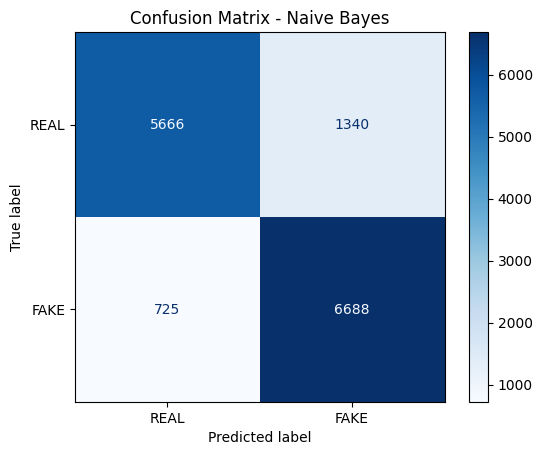

In [ ]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["REAL", "FAKE"])
disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Naive Bayes")
plt.show()

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.81      0.85      7006
           1       0.83      0.90      0.87      7413

    accuracy                           0.86     14419
   macro avg       0.86      0.86      0.86     14419
weighted avg       0.86      0.86      0.86     14419



In [ ]:
train_acc = nb_model.score(X_train_vec, y_train)
test_acc = nb_model.score(X_test_vec, y_test)

labels = ["Train Accuracy", "Test Accuracy"]
values = [train_acc, test_acc]

plt.bar(labels, values)
plt.ylim(0, 1)
plt.title("Naive Bayes Accuracy Comparison")
plt.show()

ValueError: X has 50000 features, but MultinomialNB is expecting 20000 features as input.

In [ ]:
from sklearn.metrics import log_loss

y_prob = nb_model.predict_proba(X_test_vec)

loss = log_loss(y_test, y_prob)

print("Log Loss:", loss)

Log Loss: 0.3633883060182574


In [ ]:
nb_model = joblib.load(base_path + "/naive_bayes_model.pkl")
tfidf = joblib.load(base_path + "/tfidf_nb.pkl")

In [ ]:
X_train_vec = tfidf.transform(X_train)
X_test_vec = tfidf.transform(X_test)

In [ ]:
train_acc = nb_model.score(X_train_vec, y_train)
test_acc = nb_model.score(X_test_vec, y_test)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)

Train Accuracy: 0.8614675081489701
Test Accuracy: 0.8567861848949303


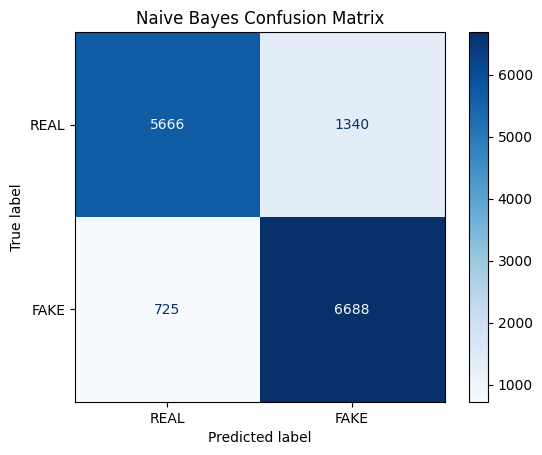

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = nb_model.predict(X_test_vec)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["REAL", "FAKE"])
disp.plot(cmap="Blues")

plt.title("Naive Bayes Confusion Matrix")
plt.show()

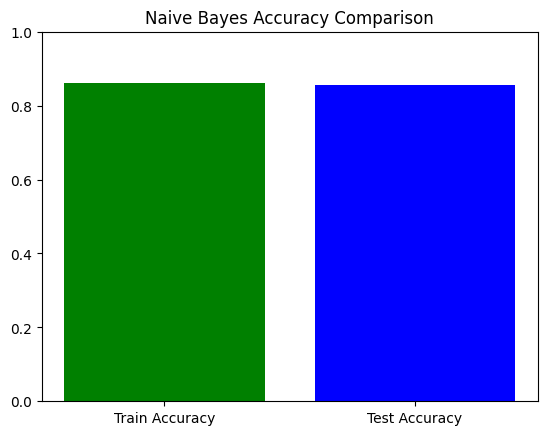

In [ ]:
import matplotlib.pyplot as plt

labels = ["Train Accuracy", "Test Accuracy"]
values = [0.8614, 0.8567]

plt.bar(labels, values, color=["green", "blue"])
plt.ylim(0, 1)
plt.title("Naive Bayes Accuracy Comparison")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.81      0.85      7006
           1       0.83      0.90      0.87      7413

    accuracy                           0.86     14419
   macro avg       0.86      0.86      0.86     14419
weighted avg       0.86      0.86      0.86     14419



In [ ]:
from sklearn.metrics import log_loss

y_prob = nb_model.predict_proba(X_test_vec)

loss = log_loss(y_test, y_prob)

print("Log Loss:", loss)

Log Loss: 0.3633883060182574


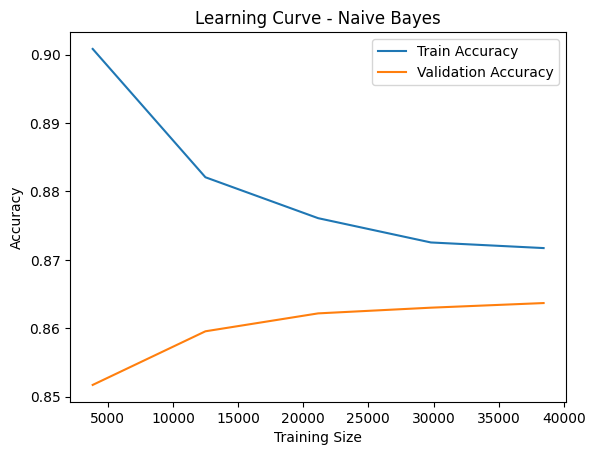

In [ ]:
from sklearn.model_selection import learning_curve
import numpy as np

train_sizes, train_scores, test_scores = learning_curve(
    nb_model,
    X_train_vec,
    y_train,
    cv=3,
    scoring="accuracy"
)

plt.plot(train_sizes, np.mean(train_scores, axis=1), label="Train Accuracy")
plt.plot(train_sizes, np.mean(test_scores, axis=1), label="Validation Accuracy")

plt.title("Learning Curve - Naive Bayes")
plt.xlabel("Training Size")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
import joblib

joblib.dump(nb_model, base_path + "/naive_bayes_model.pkl")
print("Naive Bayes model saved")

Naive Bayes model saved


In [ ]:
joblib.dump(tfidf, base_path + "/tfidf_nb.pkl")
print("TF-IDF saved")

TF-IDF saved


In [ ]:
import numpy as np

np.save(base_path + "/X_train_vec.npy", X_train_vec.toarray())
np.save(base_path + "/X_test_vec.npy", X_test_vec.toarray())
np.save(base_path + "/y_train.npy", y_train)
np.save(base_path + "/y_test.npy", y_test)

print("Dataset splits saved")

Dataset splits saved


In [ ]:
metrics = {
    "train_accuracy": train_acc,
    "test_accuracy": test_acc
}

joblib.dump(metrics, base_path + "/metrics.pkl")

print("Metrics saved")

Metrics saved


In [ ]:
import os

base_path = "/content/drive/MyDrive/TEXT MODULE"

files_to_delete = [
    "X_train_vec.npy",
    "X_test_vec.npy",
    "y_train.npy",
    "y_test.npy"
]

for f in files_to_delete:
    file_path = base_path + "/" + f
    if os.path.exists(file_path):
        os.remove(file_path)
        print(f"Deleted: {f}")
    else:
        print(f"Not found: {f}")

Deleted: X_train_vec.npy
Deleted: X_test_vec.npy
Deleted: y_train.npy
Deleted: y_test.npy


<Figure size 600x500 with 0 Axes>

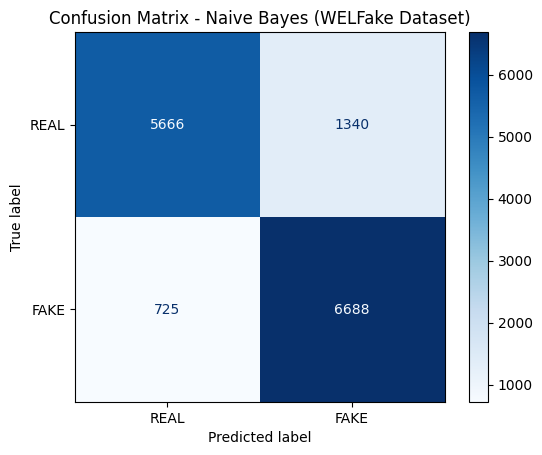

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# predictions
y_pred = nb_model.predict(X_test_vec)

# confusion matrix
cm = confusion_matrix(y_test, y_pred)

# plot
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["REAL", "FAKE"])

plt.figure(figsize=(6,5))
disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Naive Bayes (WELFake Dataset)")
plt.show()

In [ ]:
test_sentences = [
    "The government announced new education reforms.",
    "Scientists discovered a new planet in space.",
    "Aliens are secretly controlling the weather using satellites.",
    "Drinking lemon water can cure all diseases instantly.",
    "The stock market showed steady growth today.",
    "A new healthcare policy was introduced by the ministry.",
    "Time travel has been achieved by scientists.",
    "Researchers published a study on renewable energy.",
    "A hidden city of robots was found under Lahore.",
    "The central bank increased interest rates."
]

for text in test_sentences:
    vec = tfidf.transform([text])
    pred = nb_model.predict(vec)[0]

    print("TEXT:", text)
    print("PREDICTION:", "FAKE" if pred == 1 else "REAL")
    print("-"*60)

TEXT: The government announced new education reforms.
PREDICTION: REAL
------------------------------------------------------------
TEXT: Scientists discovered a new planet in space.
PREDICTION: FAKE
------------------------------------------------------------
TEXT: Aliens are secretly controlling the weather using satellites.
PREDICTION: FAKE
------------------------------------------------------------
TEXT: Drinking lemon water can cure all diseases instantly.
PREDICTION: FAKE
------------------------------------------------------------
TEXT: The stock market showed steady growth today.
PREDICTION: REAL
------------------------------------------------------------
TEXT: A new healthcare policy was introduced by the ministry.
PREDICTION: REAL
------------------------------------------------------------
TEXT: Time travel has been achieved by scientists.
PREDICTION: REAL
------------------------------------------------------------
TEXT: Researchers published a study on renewable energy.


In [ ]:
print(df["label"].value_counts())

label
1    37067
0    35028
Name: count, dtype: int64


In [ ]:
print("Train Accuracy:", nb_model.score(X_train_vec, y_train))
print("Test Accuracy:", nb_model.score(X_test_vec, y_test))

Train Accuracy: 0.8614675081489701
Test Accuracy: 0.8567861848949303


In [ ]:
import joblib

base_path = "/content/drive/MyDrive/TEXT MODULE"

# load model
model = joblib.load(base_path + "/naive_bayes_model.pkl")

# load tfidf
tfidf = joblib.load(base_path + "/tfidf_nb.pkl")

print("Model Loaded Successfully ✅")

Model Loaded Successfully ✅


In [ ]:
X_test_vec = tfidf.transform(X_test)

In [ ]:
y_pred = model.predict(X_test_vec)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("FINAL TEST ACCURACY (20% DATA):", accuracy)

FINAL TEST ACCURACY (20% DATA): 0.8567861848949303


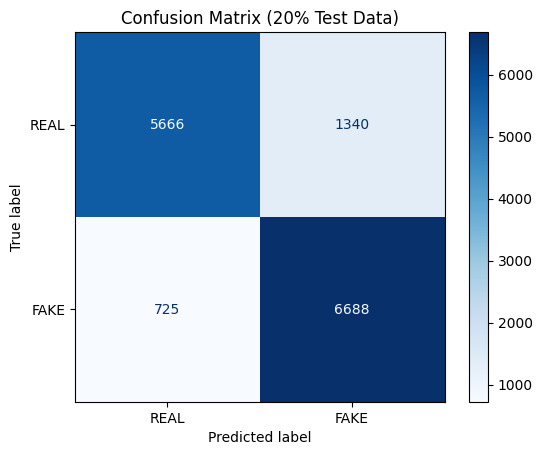

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(cm, display_labels=["REAL", "FAKE"])

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (20% Test Data)")
plt.show()

In [ ]:
import joblib

base_path = "/content/drive/MyDrive/TEXT MODULE"

# save model (final version)
joblib.dump(model, base_path + "/naive_bayes_model.pkl")

# save tfidf
joblib.dump(tfidf, base_path + "/tfidf_nb.pkl")

print("FINAL MODEL + TFIDF SAVED SUCCESSFULLY ✅")

FINAL MODEL + TFIDF SAVED SUCCESSFULLY ✅


In [ ]:
import json
from sklearn.metrics import accuracy_score

metrics = {
    "accuracy": accuracy_score(y_test, y_pred)
}

with open(base_path + "/final_metrics.json", "w") as f:
    json.dump(metrics, f)

print("Metrics saved ✅")

Metrics saved ✅


In [ ]:
import gradio as gr
import joblib

# Load model + vectorizer (Naive Bayes)
model = joblib.load("/content/drive/MyDrive/TEXT MODULE/naive_bayes_model.pkl")
tfidf = joblib.load("/content/drive/MyDrive/TEXT MODULE/tfidf_nb.pkl")


# Prediction function
def predict_news(text):
    vector = tfidf.transform([text])

    pred = model.predict(vector)[0]
    prob = model.predict_proba(vector)[0]

    confidence = max(prob) * 100

    if pred == 1:
        return f"🚨 FAKE NEWS\nConfidence: {confidence:.2f}%"
    else:
        return f"✅ REAL NEWS\nConfidence: {confidence:.2f}%"


# UPDATED CSS (keeps your blue theme + adds color result box)
custom_css = """
.gradio-container {
    background: linear-gradient(to right, #dbeafe, #93c5fd) !important;
    min-height: 100vh;
    font-family: Arial, sans-serif;
    padding: 20px;
}

/* TITLE */
#title {
    text-align: center;
    color: #1e3a8a;
    font-size: 38px;
    font-weight: 800;
}

/* SUBTITLE */
#subtitle {
    text-align: center;
    color: #1d4ed8;
    font-size: 16px;
    margin-bottom: 15px;
}

/* INFO BOX */
.info-box {
    background-color: rgba(255, 255, 255, 0.8);
    border-radius: 15px;
    padding: 16px;
    margin-top: 12px;
    border: 2px solid #60a5fa;
    color: #0f172a;
}

/* INPUT */
textarea {
    background-color: #f8fbff !important;
    border: 2px solid #3b82f6 !important;
    border-radius: 12px !important;
    font-size: 16px !important;
}

/* BUTTON */
button {
    background-color: #2563eb !important;
    color: white !important;
    border-radius: 12px !important;
    font-size: 17px !important;
    font-weight: bold !important;
    padding: 10px !important;
}

button:hover {
    background-color: #1d4ed8 !important;
}

/* OUTPUT AREA */
.output-text textarea {
    font-size: 18px !important;
    font-weight: bold !important;
    border-radius: 12px !important;
    padding: 10px !important;
}

/* FOOTER */
.footer {
    text-align: center;
    color: #1e3a8a;
    font-size: 15px;
    margin-top: 18px;
    font-weight: 600;
}
"""


# UI
with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:

    gr.Markdown("""
    <div id="title">📰 Fake News Detection System</div>
    <div id="subtitle">Naive Bayes + TF-IDF Based Machine Learning Model</div>
    """)

    gr.Markdown("""
    <div class="info-box">

    ### 📌 Project Details
    - Dataset: WELFake Dataset
    - Model: Naive Bayes (MultinomialNB)
    - Feature Extraction: TF-IDF
    - Task: Binary Classification (Real / Fake News)

    </div>
    """)

    news_input = gr.Textbox(
        lines=8,
        placeholder="Paste news article here...",
        label="📝 Enter News Article"
    )

    output = gr.Textbox(
        label="🔍 Prediction Result (with Confidence)",
        elem_classes="output-text"
    )

    btn = gr.Button("🚀 Predict News")

    btn.click(
        fn=predict_news,
        inputs=news_input,
        outputs=output
    )

    gr.Markdown("""
    <div class="footer">
    📚 Final Year Machine Learning Project
    </div>
    """)

app.launch()

/tmp/ipykernel_2963/2289687904.py:101: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:
/tmp/ipykernel_2963/2289687904.py:101: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://981fbd9ef43b6cc373.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
code = """
# paste your full gradio code here (app.py content)
"""

with open("app.py", "w") as f:
    f.write(code)

print("app.py created")

app.py created


In [ ]:
code = r'''
import gradio as gr
import joblib

# Load model + vectorizer
model = joblib.load("naive_bayes_model.pkl")
tfidf = joblib.load("tfidf_nb.pkl")


def predict_news(text):
    vector = tfidf.transform([text])

    pred = model.predict(vector)[0]
    prob = model.predict_proba(vector)[0]

    confidence = max(prob) * 100

    if pred == 1:
        return f"🚨 FAKE NEWS\nConfidence: {confidence:.2f}%"
    else:
        return f"✅ REAL NEWS\nConfidence: {confidence:.2f}%"


custom_css = """
.gradio-container {
    background: linear-gradient(to right, #dbeafe, #93c5fd) !important;
    min-height: 100vh;
    font-family: Arial, sans-serif;
    padding: 20px;
}

#title {
    text-align: center;
    color: #1e3a8a;
    font-size: 38px;
    font-weight: 800;
}

#subtitle {
    text-align: center;
    color: #1d4ed8;
    font-size: 16px;
    margin-bottom: 15px;
}

.info-box {
    background-color: rgba(255, 255, 255, 0.8);
    border-radius: 15px;
    padding: 16px;
    margin-top: 12px;
    border: 2px solid #60a5fa;
    color: #0f172a;
}

textarea {
    background-color: #f8fbff !important;
    border: 2px solid #3b82f6 !important;
    border-radius: 12px !important;
    font-size: 16px !important;
}

button {
    background-color: #2563eb !important;
    color: white !important;
    border-radius: 12px !important;
    font-size: 17px !important;
    font-weight: bold !important;
    padding: 10px !important;
}

button:hover {
    background-color: #1d4ed8 !important;
}

.output-text textarea {
    font-size: 18px !important;
    font-weight: bold !important;
    border-radius: 12px !important;
    padding: 10px !important;
}

.footer {
    text-align: center;
    color: #1e3a8a;
    font-size: 15px;
    margin-top: 18px;
    font-weight: 600;
}
"""


with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:

    gr.Markdown(\"\"\"
    <div id="title">📰 Fake News Detection System</div>
    <div id="subtitle">Naive Bayes + TF-IDF Based Machine Learning Model</div>
    \"\"\")

    gr.Markdown(\"\"\"
    <div class="info-box">

    ### 📌 Project Details
    - Dataset: WELFake Dataset
    - Model: Naive Bayes (MultinomialNB)
    - Feature Extraction: TF-IDF
    - Task: Binary Classification (Real / Fake News)

    </div>
    \"\"\")

    news_input = gr.Textbox(
        lines=8,
        placeholder="Paste news article here...",
        label="📝 Enter News Article"
    )

    output = gr.Textbox(
        label="🔍 Prediction Result (with Confidence)",
        elem_classes="output-text"
    )

    btn = gr.Button("🚀 Predict News")

    btn.click(
        fn=predict_news,
        inputs=news_input,
        outputs=output
    )

    gr.Markdown(\"\"\"
    <div class="footer">
    📚 Final Year Machine Learning Project
    </div>
    \"\"\")

app.launch()
'''

with open("app.py", "w") as f:
    f.write(code)

print("app.py created successfully")

app.py created successfully


In [ ]:
from google.colab import files
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
with open("app.py", "w") as f:
    f.write(code)

print("Saved in Colab runtime")

Saved in Colab runtime


In [ ]:
from google.colab import files
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!cp "/content/drive/MyDrive/TEXT MODULE/app.py" .
!cp "/content/drive/MyDrive/TEXT MODULE/naive_bayes_model.pkl" .
!cp "/content/drive/MyDrive/TEXT MODULE/tfidf_nb.pkl" .

cp: cannot stat '/content/drive/MyDrive/TEXT MODULE/app.py': No such file or directory


In [ ]:
from google.colab import files

files.download("app.py")
files.download("naive_bayes_model.pkl")
files.download("tfidf_nb.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import gradio as gr
import joblib

# Load model + vectorizer
model = joblib.load("naive_bayes_model.pkl")
tfidf = joblib.load("tfidf_nb.pkl")


# Prediction function
def predict_news(text):

    vector = tfidf.transform([text])

    pred = model.predict(vector)[0]
    prob = model.predict_proba(vector)[0]

    confidence = max(prob) * 100

    if pred == 1:
        return f"🚨 FAKE NEWS DETECTED\nConfidence: {confidence:.2f}%"
    else:
        return f"✅ REAL NEWS\nConfidence: {confidence:.2f}%"


# CSS (clean + professional blue theme)
custom_css = """
.gradio-container {
    background: linear-gradient(to right, #dbeafe, #93c5fd) !important;
    min-height: 100vh;
    font-family: Arial, sans-serif;
    padding: 20px;
}

#title {
    text-align: center;
    color: #1e3a8a;
    font-size: 40px;
    font-weight: bold;
}

#subtitle {
    text-align: center;
    color: #1d4ed8;
    font-size: 18px;
    margin-bottom: 10px;
}

.info-box {
    background-color: rgba(255,255,255,0.85);
    border-radius: 15px;
    padding: 15px;
    margin-top: 10px;
    border: 2px solid #60a5fa;
    color: #0f172a;
}

textarea {
    background-color: #f8fbff !important;
    border: 2px solid #3b82f6 !important;
    border-radius: 12px !important;
    font-size: 16px !important;
}

button {
    background-color: #2563eb !important;
    color: white !important;
    border-radius: 12px !important;
    font-size: 18px !important;
    font-weight: bold !important;
    padding: 10px !important;
}

button:hover {
    background-color: #1d4ed8 !important;
}

.footer {
    text-align: center;
    color: #1e3a8a;
    font-size: 15px;
    margin-top: 20px;
    font-weight: 600;
}
"""


with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:

    gr.Markdown("""
    <div id="title">📰 Fake News Detection System</div>
    <div id="subtitle">Naive Bayes + TF-IDF Machine Learning Model</div>
    """)

    gr.Markdown("""
    <div class="info-box">

    ### 👩‍💻 Developed By
    - Khadijah Irfan
    - Zujajah Khan
    - Fatima Fiaz
    - Momina Aadil

    ---

    ### 📊 Model Information
    - Algorithm: Multinomial Naive Bayes
    - Feature Extraction: TF-IDF
    - Dataset: WELFake Dataset
    - Accuracy: **85.67% (Naive Bayes Model)**

    ---

    ### 📌 Project Type
    Binary Classification (Real vs Fake News)

    </div>
    """)

    news_input = gr.Textbox(
        lines=8,
        placeholder="Paste news article here...",
        label="📝 Enter News Article"
    )

    output = gr.Textbox(
        label="🔍 Prediction Result (with Confidence)"
    )

    btn = gr.Button("🚀 Predict News")

    btn.click(
        fn=predict_news,
        inputs=news_input,
        outputs=output
    )

    gr.Markdown("""
    <div class="footer">
    📚 Final Year Project | Machine Learning Based Fake News Detection
    </div>
    """)

app.launch(share=True)

FileNotFoundError: [Errno 2] No such file or directory: 'naive_bayes_model.pkl'

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
base_path = "/content/drive/MyDrive/TEXT MODULE"

In [3]:
import pandas as pd
import numpy as np
import joblib

In [4]:
model = joblib.load(base_path + "/fake_news_model.pkl")
tfidf = joblib.load(base_path + "/tfidf.pkl")

In [5]:
model = joblib.load(base_path + "/final_svm_model.pkl")
tfidf = joblib.load(base_path + "/final_tfidf.pkl")

In [6]:
text = "The government announced new healthcare reforms."

vec = tfidf.transform([text])

prediction = model.predict(vec)

print(prediction)

[1]


In [7]:
if prediction[0] == 0:
    print("REAL NEWS")
else:
    print("FAKE NEWS")

FAKE NEWS


In [8]:
text = "Aliens secretly control the weather."

vec = tfidf.transform([text])

prediction = model.predict(vec)

if prediction[0] == 0:
    print("REAL NEWS")
else:
    print("FAKE NEWS")

FAKE NEWS


In [10]:
!pip install gradio

In [11]:
import os
print(os.listdir("/content/drive/MyDrive/TEXT MODULE"))

['WELFake_Dataset.csv', 'final_svm_model.pkl', 'final_tfidf.pkl', 'fake_news_model.pkl', 'tfidf.pkl', 'naive_bayes_model_backup.pkl', 'tfidf_nb_backup.pkl', 'metrics.pkl', 'naive_bayes_model.pkl', 'tfidf_nb.pkl', 'final_metrics.json']


In [12]:
from google.colab import drive
drive.mount('/content/drive')

import gradio as gr
import joblib

base_path = "/content/drive/MyDrive/TEXT MODULE"

# Load saved files
model = joblib.load(base_path + "/naive_bayes_model.pkl")
tfidf = joblib.load(base_path + "/tfidf_nb.pkl")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
!pip install gradio -q

In [16]:
text = "The government approved a new education policy."

vec = tfidf.transform([text])

prediction = model.predict(vec)

print(prediction)

[0]


In [22]:
import gradio as gr
import joblib

# Load model + vectorizer
model = joblib.load("naive_bayes_model.pkl")
tfidf = joblib.load("tfidf_nb.pkl")


# Prediction function
def predict_news(text):

    vector = tfidf.transform([text])

    pred = model.predict(vector)[0]
    prob = model.predict_proba(vector)[0]

    confidence = max(prob) * 100

    if pred == 1:
        return f"🚨 FAKE NEWS DETECTED\nConfidence: {confidence:.2f}%"
    else:
        return f"✅ REAL NEWS\nConfidence: {confidence:.2f}%"


# CSS (clean + professional blue theme)
custom_css = """
.gradio-container {
    background: linear-gradient(to right, #dbeafe, #93c5fd) !important;
    min-height: 100vh;
    font-family: Arial, sans-serif;
    padding: 20px;
}

#title {
    text-align: center;
    color: #1e3a8a;
    font-size: 40px;
    font-weight: bold;
}

#subtitle {
    text-align: center;
    color: #1d4ed8;
    font-size: 18px;
    margin-bottom: 10px;
}

.info-box {
    background-color: rgba(255,255,255,0.85);
    border-radius: 15px;
    padding: 15px;
    margin-top: 10px;
    border: 2px solid #60a5fa;
    color: #0f172a;
}

textarea {
    background-color: #f8fbff !important;
    border: 2px solid #3b82f6 !important;
    border-radius: 12px !important;
    font-size: 16px !important;
}

button {
    background-color: #2563eb !important;
    color: white !important;
    border-radius: 12px !important;
    font-size: 18px !important;
    font-weight: bold !important;
    padding: 10px !important;
}

button:hover {
    background-color: #1d4ed8 !important;
}

.footer {
    text-align: center;
    color: #1e3a8a;
    font-size: 15px;
    margin-top: 20px;
    font-weight: 600;
}
"""


with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:

    gr.Markdown("""
    <div id="title">📰 Fake News Detection System</div>
    <div id="subtitle">Naive Bayes + TF-IDF Machine Learning Model</div>
    """)

    gr.Markdown("""
    <div class="info-box">

    ### 👩‍💻 Developed By
    - Khadijah Irfan
    - Zujajah Khan
    - Fatima Fiaz
    - Momina Aadil

    ---

    ### 📊 Model Information
    - Algorithm: Multinomial Naive Bayes
    - Feature Extraction: TF-IDF
    - Dataset: WELFake Dataset
    - Accuracy: **85.67% (Naive Bayes Model)**

    ---

    ### 📌 Project Type
    Binary Classification (Real vs Fake News)

    </div>
    """)

    news_input = gr.Textbox(
        lines=8,
        placeholder="Paste news article here...",
        label="📝 Enter News Article"
    )

    output = gr.Textbox(
        label="🔍 Prediction Result (with Confidence)"
    )

    btn = gr.Button("🚀 Predict News")

    btn.click(
        fn=predict_news,
        inputs=news_input,
        outputs=output
    )

    gr.Markdown("""
    <div class="footer">
    📚 Final Year Project | Machine Learning Based Fake News Detection
    </div>
    """)

app.launch(share=True)

FileNotFoundError: [Errno 2] No such file or directory: 'naive_bayes_model.pkl'

In [19]:
base_path = "/content/drive/MyDrive/TEXT MODULE"

model = joblib.load(base_path + "/naive_bayes_model.pkl")
tfidf = joblib.load(base_path + "/tfidf_nb.pkl")

In [21]:
from google.colab import drive
drive.mount('/content/drive')

import gradio as gr
import joblib

base_path = "/content/drive/MyDrive/TEXT MODULE"

# Load model + vectorizer
model = joblib.load(base_path + "/naive_bayes_model.pkl")
tfidf = joblib.load(base_path + "/tfidf_nb.pkl")

print("Everything Loaded Successfully")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Everything Loaded Successfully


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os

print(os.listdir("/content/drive/MyDrive/TEXT MODULE"))

['WELFake_Dataset.csv', 'final_svm_model.pkl', 'final_tfidf.pkl', 'fake_news_model.pkl', 'tfidf.pkl', 'naive_bayes_model_backup.pkl', 'tfidf_nb_backup.pkl', 'metrics.pkl', 'naive_bayes_model.pkl', 'tfidf_nb.pkl', 'final_metrics.json']


In [3]:
base_path = "/content/drive/MyDrive/TEXT MODULE"

In [4]:
import joblib

model = joblib.load(base_path + "/naive_bayes_model.pkl")
tfidf = joblib.load(base_path + "/tfidf_nb.pkl")

print("Loaded Successfully")

Loaded Successfully


In [5]:
text = "The government announced new education reforms."

vec = tfidf.transform([text])
print(model.predict(vec))

[0]


In [6]:
!pip install gradio -q

In [7]:
import gradio as gr

def predict(text):
    vec = tfidf.transform([text])
    pred = model.predict(vec)[0]

    return "FAKE NEWS 🚨" if pred == 1 else "REAL NEWS ✅"

app = gr.Interface(
    fn=predict,
    inputs="text",
    outputs="text",
    title="Fake News Detection"
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8703ffdbb77df7a784.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [8]:
import gradio as gr
import joblib
from google.colab import drive

# =========================
# 1. MOUNT GOOGLE DRIVE
# =========================
drive.mount('/content/drive')

# =========================
# 2. LOAD MODEL + VECTORIZER
# =========================
base_path = "/content/drive/MyDrive/TEXT MODULE"

model = joblib.load(base_path + "/naive_bayes_model.pkl")
tfidf = joblib.load(base_path + "/tfidf_nb.pkl")

print("Model and TF-IDF loaded successfully")

# =========================
# 3. PREDICTION FUNCTION
# =========================
def predict_news(text):

    vector = tfidf.transform([text])

    pred = model.predict(vector)[0]
    prob = model.predict_proba(vector)[0]

    confidence = max(prob) * 100

    if pred == 1:
        return f"🚨 FAKE NEWS DETECTED\nConfidence: {confidence:.2f}%"
    else:
        return f"✅ REAL NEWS DETECTED\nConfidence: {confidence:.2f}%"

# =========================
# 4. CUSTOM CSS
# =========================
custom_css = """
.gradio-container {
    background: linear-gradient(to right, #dbeafe, #93c5fd) !important;
    min-height: 100vh;
    font-family: Arial, sans-serif;
    padding: 20px;
}

#title {
    text-align: center;
    color: #1e3a8a;
    font-size: 40px;
    font-weight: bold;
}

#subtitle {
    text-align: center;
    color: #1d4ed8;
    font-size: 18px;
    margin-bottom: 10px;
}

.info-box {
    background-color: rgba(255,255,255,0.85);
    border-radius: 15px;
    padding: 15px;
    margin-top: 10px;
    border: 2px solid #60a5fa;
    color: #0f172a;
}

textarea {
    background-color: #f8fbff !important;
    border: 2px solid #3b82f6 !important;
    border-radius: 12px !important;
    font-size: 16px !important;
}

button {
    background-color: #2563eb !important;
    color: white !important;
    border-radius: 12px !important;
    font-size: 18px !important;
    font-weight: bold !important;
    padding: 10px !important;
}

button:hover {
    background-color: #1d4ed8 !important;
}

.footer {
    text-align: center;
    color: #1e3a8a;
    font-size: 15px;
    margin-top: 20px;
    font-weight: 600;
}
"""

# =========================
# 5. GRADIO UI
# =========================
with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:

    gr.Markdown("""
    <div id="title">📰 Fake News Detection System</div>
    <div id="subtitle">Naive Bayes + TF-IDF Machine Learning Model</div>
    """)

    gr.Markdown("""
    <div class="info-box">

    ### 👩‍💻 Developed By
    - Khadijah Irfan
    - Zujajah Khan
    - Fatima Fiaz
    - Momina Aadil

    ---

    ### 📊 Model Information
    - Algorithm: Multinomial Naive Bayes
    - Feature Extraction: TF-IDF
    - Dataset: WELFake Dataset
    - Accuracy: 85.67%

    ---

    ### 📌 Project Type
    Binary Classification (Real vs Fake News)

    </div>
    """)

    news_input = gr.Textbox(
        lines=8,
        placeholder="Paste news article here...",
        label="📝 Enter News Article"
    )

    output = gr.Textbox(label="🔍 Prediction Result (with Confidence)")

    btn = gr.Button("🚀 Predict News")

    btn.click(
        fn=predict_news,
        inputs=news_input,
        outputs=output
    )

    gr.Markdown("""
    <div class="footer">
    📚 Final Year Project | Machine Learning Based Fake News Detection
    </div>
    """)

# =========================
# 6. LAUNCH APP
# =========================
app.launch(share=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model and TF-IDF loaded successfully


/tmp/ipykernel_5628/3296492229.py:103: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:
/tmp/ipykernel_5628/3296492229.py:103: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Soft()) as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3370015d37a78f28be.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [10]:
from google.colab import drive
drive.mount('/content/drive')

import joblib
import pandas as pd

base_path = "/content/drive/MyDrive/TEXT MODULE"

print("Files in folder:")
import os
print(os.listdir(base_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files in folder:
['WELFake_Dataset.csv', 'final_svm_model.pkl', 'final_tfidf.pkl', 'fake_news_model.pkl', 'tfidf.pkl', 'naive_bayes_model_backup.pkl', 'tfidf_nb_backup.pkl', 'metrics.pkl', 'naive_bayes_model.pkl', 'tfidf_nb.pkl', 'final_metrics.json']


In [11]:
model = joblib.load(base_path + "/naive_bayes_model.pkl")
tfidf = joblib.load(base_path + "/tfidf_nb.pkl")

print("MODEL LOADED SUCCESSFULLY")

MODEL LOADED SUCCESSFULLY


In [12]:
df = pd.read_csv(base_path + "/WELFake_Dataset.csv")

df = df.dropna(subset=["text"])

X = df["text"]
y = df["label"]

In [13]:
X_vec = tfidf.transform(X)
pred = model.predict(X_vec)

In [14]:
from sklearn.metrics import accuracy_score

print("ACCURACY:", accuracy_score(y, pred))

ACCURACY: 0.8605312434981621


In [15]:
texts = [
    "The government announced new healthcare reforms.",
    "Aliens secretly control weather systems.",
    "Stock market shows strong growth today.",
    "Scientists discovered a new element."
]

for t in texts:
    vec = tfidf.transform([t])
    print(t)
    print("Prediction:", model.predict(vec)[0])
    print("-"*40)

The government announced new healthcare reforms.
Prediction: 0
----------------------------------------
Aliens secretly control weather systems.
Prediction: 1
----------------------------------------
Stock market shows strong growth today.
Prediction: 1
----------------------------------------
Scientists discovered a new element.
Prediction: 1
----------------------------------------


In [16]:
from sklearn.metrics import classification_report

print(classification_report(y, pred))

              precision    recall  f1-score   support

           0       0.89      0.82      0.85     35028
           1       0.84      0.90      0.87     37067

    accuracy                           0.86     72095
   macro avg       0.86      0.86      0.86     72095
weighted avg       0.86      0.86      0.86     72095



In [18]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y, pred))

[[28599  6429]
 [ 3626 33441]]


In [21]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [22]:
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

In [23]:
y_pred = model.predict(X_test_vec)

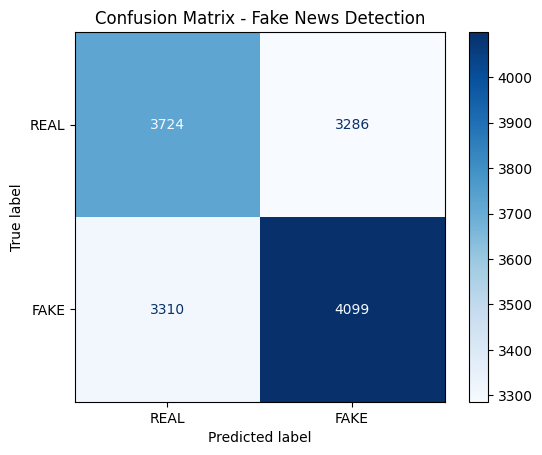

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(cm, display_labels=["REAL", "FAKE"])
disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Fake News Detection")
plt.show()

IMPORT LIBRARIES

In [26]:
import pandas as pd
import numpy as np
import joblib
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


MOUNT DRIVE

In [27]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


LOAD DATASET

In [28]:
base_path = "/content/drive/MyDrive/TEXT MODULE"

df = pd.read_csv(base_path + "/WELFake_Dataset.csv")


BASIC DATA CHECK

In [29]:
df.head()

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [30]:
df.columns

Index(['Unnamed: 0', 'title', 'text', 'label'], dtype='object')

In [31]:
df.shape

(72134, 4)

In [32]:
df.isnull().sum()

,0
Unnamed: 0,0
title,558
text,39
label,0


In [33]:
df['label'].value_counts()

,count
label,
1,37106
0,35028


DATA CLEANING

In [34]:
df = df.dropna(subset=["text"])
df["content"] = df["text"]


SPLIT DATA

In [35]:
X = df["content"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


TF-IDF VECTORIZATION

In [36]:
tfidf = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1,2),
    max_df=0.7,
    min_df=5
)

X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)


Training

In [37]:
model = MultinomialNB()
model.fit(X_train_vec, y_train)


MultinomialNB()

Prediction

In [38]:
y_pred = model.predict(X_test_vec)

Accuracy

In [39]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8891740065191761


In [40]:
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Confusion Matrix:
 [[6257  753]
 [ 845 6564]]


Classification Report

In [41]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.89      0.89      7010
           1       0.90      0.89      0.89      7409

    accuracy                           0.89     14419
   macro avg       0.89      0.89      0.89     14419
weighted avg       0.89      0.89      0.89     14419



Saving Model

In [42]:
joblib.dump(model, base_path + "/naive_bayes_model.pkl")
joblib.dump(tfidf, base_path + "/tfidf_nb.pkl")


['/content/drive/MyDrive/TEXT MODULE/tfidf_nb.pkl']

In [43]:
model = joblib.load(base_path + "/naive_bayes_model.pkl")
tfidf = joblib.load(base_path + "/tfidf_nb.pkl")


In [44]:
text = "The government announced new education reforms."

vec = tfidf.transform([text])
print(model.predict(vec))


[0]


In [45]:
import joblib

base_path = "/content/drive/MyDrive/TEXT MODULE"

joblib.dump(model, base_path + "/naive_bayes_model.pkl")
joblib.dump(tfidf, base_path + "/tfidf_nb.pkl")

print("Model and TF-IDF saved successfully")

Model and TF-IDF saved successfully


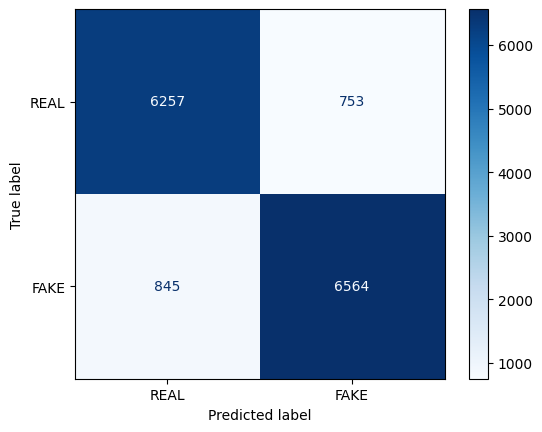

Confusion matrix saved


In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(cm, display_labels=["REAL", "FAKE"])
disp.plot(cmap="Blues")

plt.savefig(base_path + "/confusion_matrix.png")
plt.show()

print("Confusion matrix saved")

In [47]:
import os

print(os.listdir(base_path))

['WELFake_Dataset.csv', 'final_svm_model.pkl', 'final_tfidf.pkl', 'fake_news_model.pkl', 'tfidf.pkl', 'naive_bayes_model_backup.pkl', 'tfidf_nb_backup.pkl', 'metrics.pkl', 'naive_bayes_model.pkl', 'tfidf_nb.pkl', 'final_metrics.json', 'confusion_matrix.png']
